# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Устройство: Kaggle, одна GPU Tesla T4 (torch 2.11.0+cu130, transformers 5.22.1, datasets 5.1.0, Python 3.13). Модель: DeepPavlov/rubert-base-cased (https://huggingface.co/DeepPavlov/rubert-base-cased), revision 4036cab694767a299f2b9e6492909664d9414229; лицензия в карточке на Hub не указана (license: None). Для бонуса 6.2 использована cointegrated/rubert-tiny2 (https://huggingface.co/cointegrated/rubert-tiny2), revision e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae, лицензия MIT. Датасет: RCC-MSU/collection3, ветка refs/convert/parquet (https://huggingface.co/datasets/RCC-MSU/collection3), лицензия в карточке "other", раздел Licensing Information не заполнен. Бонусы: 6.1, 6.2, 6.3, 6.4, 6.5. Источники: документация transformers, datasets, seqeval и PyTorch, карточки моделей и датасета на Hugging Face. В сохранённом ноутбуке отсутствуют виджетные прогресс-бары (tqdm). Добавила вспомогательные ячейки (получение хеша ревизии, вывод предложений с невалидным BIO, сохранение bonus_metrics.json в artifacts). Нерешённых задач нет.

In [ ]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

torch 2.11.0+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [ ]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [ ]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}  # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [ ]:
from huggingface_hub import HfApi
print(HfApi().model_info('DeepPavlov/rubert-base-cased').sha)

4036cab694767a299f2b9e6492909664d9414229


In [ ]:
MODEL_ID = 'DeepPavlov/rubert-base-cased'
REVISION = '4036cab694767a299f2b9e6492909664d9414229'
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [ ]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    DeepPavlov/rubert-base-cased
revision: 4036cab694767a299f2b9e6492909664d9414229
license:  None
language: ['ru']
updated:  2021-11-23 08:03:04+00:00
weights:  {'pytorch_model.bin': '681 MB'}


BertTokenizer vocab size 119547
['Петр', 'Ильич', 'Чайковский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Я выбрала DeepPavlov/rubert-base-cased: язык русский, по карточке это BERT-base (12 слоёв, hidden 768, 180M параметров), обученный на русской части Википедии и новостях, со словарём русских сабвордов (инициализация от мультиязычного BERT-base), что подходит под русские новости Collection3, а размер даёт приемлемое время на T4 (минуты - десятки минут), так как архитектура base обучается и делает инференс значительно быстрее тяжелых large-моделей; ожидаемый f1-score на NER в диапазоне 85% - 90%. Альтернатива: cointegrated/rubert-tiny2 (29M параметров, MIT, язык русский) я буду обучать в бонусе 6.2, она примерно в 6 раз компактнее выбранной DeepPavlov/rubert-base-cased; за счет облегченной 3-слойной архитектуры и сжатого словаря она обеспечивает высокую скорость обучения и инференса (минуты - десятки минут); предположительно опираясь на исследования в структурных задачах вроде NER будет уступать rubert-base-cased от 2% до 5% по f1-score из-за ограниченной емкости параметров. Лицензия rubert-base-cased на Hub не указана (license: None). Если не фиксировать revision, владелец может перезалить веса, токенизатор или конфиг, и main начнёт указывать на другую версию: токенизация и метрики могут измениться, код сломаться, репозиторий может быть переименован или удалён, и результаты ноутбука перестанут воспроизводиться.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [ ]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

{'model_type': 'bert', 'vocab_size': 119547, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [ ]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    n = lambda m: sum(p.numel() for p in m.parameters())
    base = model.base_model
    layers = [n(layer) for layer in base.encoder.layer]
    embeddings = n(base.embeddings)
    encoder = sum(layers)
    head = n(model.classifier)
    total = n(model)
    return {'embeddings': embeddings, 'encoder': encoder, 'head': head, 'other': total - embeddings - encoder - head, 'layers': layers}

In [ ]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    92,208,384   52.0%
encoder       85,054,464   48.0%
head               5,383    0.0%
other                  0    0.0%
total        177,268,231
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [ ]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]', tuple(h.shape))
print('logits', tuple(out.logits.shape))

input_ids (2, 10)
attention_mask (2, 10)
hidden_states[0] (2, 10, 768)
hidden_states[1] (2, 10, 768)
hidden_states[2] (2, 10, 768)
hidden_states[3] (2, 10, 768)
hidden_states[4] (2, 10, 768)
hidden_states[5] (2, 10, 768)
hidden_states[6] (2, 10, 768)
hidden_states[7] (2, 10, 768)
hidden_states[8] (2, 10, 768)
hidden_states[9] (2, 10, 768)
hidden_states[10] (2, 10, 768)
hidden_states[11] (2, 10, 768)
hidden_states[12] (2, 10, 768)
logits (2, 10, 7)


In [ ]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 103.3 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Вход (2 предложения по 6 слов) токенизируется в input_ids и attention_mask формы (2, 10): сабворды плюс [CLS] и [SEP], второе предложение дополнено паддингом до длины самого длинного. Блок эмбеддингов (токен + позиция + тип сегмента, LayerNorm, dropout) даёт hidden_states[0] формы (2, 10, 768), затем 12 одинаковых слоёв энкодера, каждый (2, 10, 768) -> (2, 10, 768), всего 13 тензоров hidden_states; голова (dropout + Linear 768 -> 7) даёт logits (2, 10, 7). Больше всего параметров в эмбеддингах: 92208384 (52.0%) против 85054464 (48.0%) в 12 слоях энкодера (по 7087872 на слой); голова всего 5383, other = 0. Причина в словаре: таблица 119547 * 768 даёт приблизительно 91.8M параметров, то есть почти весь блок эмбеддингов. Токены обмениваются информацией в слоях энкодера (внимание между позициями); эмбеддинги (поиск в таблице) и голова (один и тот же Linear для каждой позиции) обрабатывают каждый токен независимо. T=10 больше числа слов (6), потому что токенизатор режет редкие слова на сабворды (Воткинске -> Вот, ##кинс, ##ке) и добавляет [CLS] и [SEP].

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [ ]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [ ]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
_ds = load_dataset(DATASET_ID, revision='refs/convert/parquet')
print(_ds)
print(_ds['train'].features)

_alias = {'dev': 'validation', 'val': 'validation', 'valid': 'validation'}
raw = DatasetDict({_alias.get(k, k): v for k, v in _ds.items()})
assert {'train', 'validation', 'test'} <= set(raw), f'сплиты: {list(raw)}'

feat = raw['train'].features['ner_tags']
LABEL_NAMES = list(feat.feature.names)
print(LABEL_NAMES)
print(list(zip(raw['train'][0]['tokens'], [LABEL_NAMES[i] for i in raw['train'][0]['ner_tags']])))

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
{'id': Value('string'), 'tokens': List(Value('string')), 'ner_tags': List(ClassLabel(names=['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']))}
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Дополнение', 'O'), (':', 'O'), ('Д', 'B-PER'), ('.', 'I-PER'), ('Медведев', 'I-PER'), ('присвоил', 'O'), ('звания', 'O'), ('сотрудников', 'O'), ('полиции', 'O'), ('и', 'O'), ('переназначил', 'O'), ('14', 'O'), ('руководителей', 'O'), ('УВД', 'B-ORG'), (',', 'O'), ('ГУВД', 'B-ORG'), ('и', 'O'), ('МВД', 'B-ORG'), ('по', 'O'), ('субъектам', 'O'), ('РФ', 'B-LOC'), ('.', 'O')]


train: 9301 предложений | длина в словах: mean 20.2, median 18, p95 41, max 256
   сущности: {'PER': 7406, 'ORG': 5960, 'LOC': 4881} | всего 18247 | доля предложений без сущностей: 19.5%
validation: 2153 предложений | длина в словах: mean 20.4, median 18, p95 41, max 118
   сущности: {'PER': 1641, 'LOC': 1168, 'ORG': 1308} | всего 4117 | доля предложений без сущностей: 23.4%
test: 1922 предложений | длина в словах: mean 20.9, median 19, p95 42, max 122
   сущности: {'PER': 1570, 'LOC': 1175, 'ORG': 1256} | всего 4001 | доля предложений без сущностей: 18.3%

длина спана (слов), train+val+test:
  LOC   n=   7224 mean 1.31 median 1 max 8
  ORG   n=   8524 mean 1.98 median 1 max 18
  PER   n=  10617 mean 2.02 median 2 max 10

распределение длин спанов, % (1, 2, 3, 4 слова и 5+):
  LOC   [78.2, 15.2, 5.1, 0.5] 0.9
  ORG   [54.0, 24.5, 9.7, 5.1] 6.8
  PER   [26.7, 52.6, 17.6, 0.7] 2.4


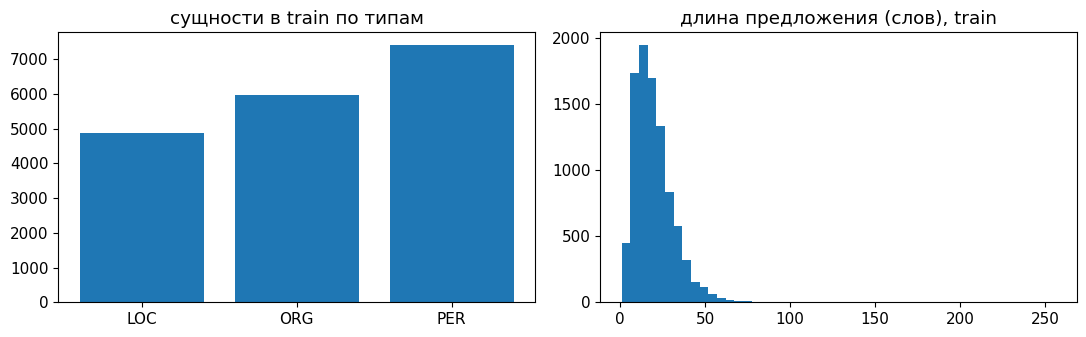

In [ ]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
from seqeval.metrics.sequence_labeling import get_entities

stats = {}
span_lens = collections.defaultdict(list)
for split, ds in raw.items():
    cnt = collections.Counter()
    for tags in ds['ner_tags']:
        for typ, s, e in get_entities([LABEL_NAMES[i] for i in tags]):
            cnt[typ] += 1
            span_lens[typ].append(e - s + 1)
    stats[split] = cnt
    sent_len = np.array([len(t) for t in ds['tokens']])
    print(f'{split}: {len(ds)} предложений | длина в словах: mean {sent_len.mean():.1f}, '
          f'median {np.median(sent_len):.0f}, p95 {np.percentile(sent_len, 95):.0f}, max {sent_len.max()}')
    print('   сущности:', dict(cnt), '| всего', sum(cnt.values()),
          '| доля предложений без сущностей: %.1f%%' % (100 * np.mean([all(t == 0 for t in tags) for tags in ds['ner_tags']])))

print('\nдлина спана (слов), train+val+test:')
for typ in sorted(span_lens):
    a = np.array(span_lens[typ])
    print(f'  {typ:<5} n={len(a):>7} mean {a.mean():.2f} median {np.median(a):.0f} max {a.max()}')

print('\nраспределение длин спанов, % (1, 2, 3, 4 слова и 5+):')
for typ in sorted(span_lens):
    a = np.array(span_lens[typ])
    print(f'  {typ:<5}', [round(100 * float(np.mean(a == k)), 1) for k in (1, 2, 3, 4)], round(100 * float(np.mean(a >= 5)), 1))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(sorted(stats['train']), [stats['train'][t] for t in sorted(stats['train'])])
ax[0].set_title('сущности в train по типам')
ax[1].hist([len(t) for t in raw['train']['tokens']], bins=50)
ax[1].set_title('длина предложения (слов), train')
plt.tight_layout(); plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Датасет Collection3 (RCC-MSU/collection3 на Hub, оригинал: Mozharova & Loukachevitch, 2016): русские новостные тексты на основе корпуса Persons-1000, в карточке указано, что размечали вручную по инструкциям, близким к MUC-7, в инструменте Brat; в BIO (IOB2) и сплиты train/validation/test конвертировала команда DeepPavlov. Лицензия в карточке "other". Три типа: PER, ORG, LOC. Размер: 9301 / 2153 / 1922 предложений; сущностей в train PER 7406, ORG 5960, LOC 4881 (всего 18 247), в validation 1641 / 1308 / 1168 (4117), в test 1570 / 1256 / 1175 (4001); всего 26 365. Совсем редких типов нет, самый редкий LOC (26.7% спанов train), PER частый (40.6%). Длины спанов в словах: LOC в среднем 1.31 (78.2% из одного слова), ORG 1.98 (54.0% из одного слова, но 6.8% длиннее 4 слов, максимум 18), PER 2.02 (52.6% из двух слов, максимум 10). Предложения короткие (среднее 20.2 слова, медиана 18, p95 41 для train), но в train есть предложение до 256 слов, длиннее лимита 128 сабвордов; без сущностей 19.5% / 23.4% / 18.3% предложений. Что может повлиять на обучение: многословные ORG и разнобой границ (кавычки, титулы, аббревиатуры), из-за чего ORG труднее всего; предложения с невалидным BIO; разметка ручная, но не идеальная.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [ ]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, start, cur = [], 0, None
    for i, t in enumerate(list(tags) + ['O']):
        if t == 'O':
            if cur is not None:
                spans.append((start, i, cur))
                cur = None
            continue
        prefix, typ = t.split('-', 1)
        if prefix == 'B' or typ != cur:
            if cur is not None:
                spans.append((start, i, cur))
            start, cur = i, typ
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for s, e, typ in spans:
        tags[s] = 'B-' + typ
        for j in range(s + 1, e):
            tags[j] = 'I-' + typ
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    out, prev = [], None
    for w in word_ids:
        if w is None:
            out.append(-100)
        elif w != prev:
            out.append(word_labels[w])
        elif b_to_i is None:
            out.append(-100)
        else:
            out.append(b_to_i.get(word_labels[w], word_labels[w]))
        prev = w
    return out

In [ ]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [ ]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
Path('data').mkdir(exist_ok=True)
n_invalid_total = 0
for split, ds in raw.items():
    with open(f'data/{split}_spans.jsonl', 'w', encoding='utf-8') as f:
        for ex in ds:
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            f.write(json.dumps({'tokens': ex['tokens'], 'spans': bio_to_spans(tags)}, ensure_ascii=False) + '\n')

    n_exact = n_invalid = n_span_ok = 0
    with open(f'data/{split}_spans.jsonl', encoding='utf-8') as f:
        for line, ex in zip(f, ds):
            rec = json.loads(line)
            orig = [LABEL_NAMES[i] for i in ex['ner_tags']]
            back = spans_to_bio([tuple(s) for s in rec['spans']], len(rec['tokens']))
            n_span_ok += bio_to_spans(back) == bio_to_spans(orig)
            if back == orig:
                n_exact += 1
            else:
                n_invalid += 1
    n_invalid_total += n_invalid
    assert n_span_ok == len(ds), 'спаны после круга туда-обратно должны совпасть'
    print(f'{split}: {len(ds)} предложений, дословно совпало {n_exact}, '
          f'отличаются только записью (I- без B-) {n_invalid}, спаны совпали во всех {n_span_ok}')

train: 9301 предложений, дословно совпало 9296, отличаются только записью (I- без B-) 5, спаны совпали во всех 9301
validation: 2153 предложений, дословно совпало 2153, отличаются только записью (I- без B-) 0, спаны совпали во всех 2153
test: 1922 предложений, дословно совпало 1921, отличаются только записью (I- без B-) 1, спаны совпали во всех 1922


In [ ]:
for split, ds in raw.items():
    for i, ex in enumerate(ds):
        tags = [LABEL_NAMES[t] for t in ex['ner_tags']]
        if spans_to_bio(bio_to_spans(tags), len(tags)) != tags:
            print(split, i, [(w, t) for w, t in zip(ex['tokens'], tags) if t != 'O'])

train 1751 [('Мособлдума', 'B-ORG'), ('Воробьева', 'B-PER'), ('о', 'I-PER'), ('Подмосковья', 'B-LOC')]
train 2524 [('Власть', 'I-ORG'), ('Вероника', 'B-PER'), ('Куцылло', 'I-PER')]
train 3143 [('Ответственность', 'I-ORG'), ('.', 'I-ORG')]
train 3144 [('Процветание', 'I-ORG'), ('09', 'I-ORG'), ('"', 'I-ORG'), ('(', 'I-ORG'), ('TOP', 'I-ORG'), ('09', 'I-ORG'), (')', 'I-ORG'), ('Чешская', 'B-ORG'), ('социал', 'I-ORG'), ('-', 'I-ORG'), ('демократическая', 'I-ORG'), ('партия', 'I-ORG'), ('(', 'I-ORG'), ('CSSD', 'I-ORG'), (')', 'I-ORG'), ('Коммунистическая', 'B-ORG'), ('партия', 'I-ORG'), ('Чехии', 'I-ORG'), ('и', 'I-ORG'), ('Моравии', 'I-ORG'), ('(', 'I-ORG'), ('KSCM', 'I-ORG'), (')', 'I-ORG'), ('Чехии', 'B-LOC'), ('Милош', 'B-PER'), ('Земан', 'I-PER')]
train 7335 [('Северный', 'I-ORG'), ('Кавказ', 'I-ORG'), ('Игорь', 'B-PER'), ('Бестужий', 'I-PER'), ('Пальцев', 'B-PER'), ('Иван', 'B-PER'), ('Богданов', 'I-PER')]
test 1242 [('Первоуральск', 'I-ORG'), ('Ольгу', 'B-PER'), ('Вертлюгову', 'I-PE

In [ ]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9291 предложений, обрезано по MAX_LENGTH 7, слов без сабвордов или за обрезкой 369
[CLS]            None  -100
Дополнение          0  O
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##знач             10  -100
##ил               10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и                  16  O
МВД               

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метка ставится на первый сабворд слова, потому что разметка и метрики по словам, и одному слову нужен один тег, а продолжения (##...) не должны дублировать или искажать его. Значение -100 это ignore_index у cross-entropy: такие позиции ([CLS], [SEP], паддинг и продолжения слов) не входят ни в loss, ни в градиент. В train из 9301 предложений проверка прошла на 9291, то есть 10 предложений потеряли часть слов; в 7 предложениях длина достигла лимита MAX_LENGTH = 128 сабвордов, всего слов без сабвордов или за обрезкой 369, это около 0.2% от ~188000 слов train. При обучении такие слова просто не участвуют в loss, а при предсказании получают O, поэтому сущности в обрезанном хвосте считаются пропущенными (небольшой минус к recall). При конвертации (датасет уже в BIO, я сделала экспорт в спаны JSON, чтение и обратную сборку) спаны совпали во всех 9301 / 2153 / 1922 предложениях, но дословно не совпали 6 предложений (5 в train, 1 в test) с невалидным BIO: I-X без B-X (5 раз I-ORG и 1 раз I-PER после тега O или в начале предложения); мой bio_to_spans начинает в таком случае новый спан, поэтому обратная запись даёт B-X. Пересекающихся или вложенных спанов нет, расхождения токенизации между словами датасета и спанами нет, различие только в разбиении на сабворды, которое обрабатывает align_labels.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [ ]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [ ]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for w, t in zip(words, tags):
            counts[w][t] += 1
    return {w: c.most_common(1)[0][0] for w, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(w, 'O') for w in words]

In [ ]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_tokens = [list(ws) for ws in data['train']['tokens']]
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(train_tokens, train_tags)
baseline = {}
baseline['majority'] = entity_scores(val_gold, [predict_majority(tagger, ws) for ws in val_tokens])

set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, random_pred)
print('majority   ', {k: round(float(v), 4) for k, v in baseline['majority'].items()})
print('random head', {k: round(float(v), 4) for k, v in baseline['random_head'].items()})
print('что предсказывает случайная голова:', collections.Counter(t for ts in random_pred for t in ts).most_common(5))
del random_model

majority    {'f1_micro': 0.5613, 'f1_macro': 0.5786, 'precision': 0.5626, 'recall': 0.5601}
random head {'f1_micro': 0.025, 'f1_macro': 0.0224, 'precision': 0.0143, 'recall': 0.0984}
что предсказывает случайная голова: [('I-PER', 11198), ('B-LOC', 9650), ('O', 7940), ('B-PER', 4915), ('I-LOC', 4649)]


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн даёт f1 micro по сущностям 0.5613 на validation (precision 0.5626, recall 0.5601, macro 0.5786). Это сопоставимо с долей спанов, которые целиком состоят из слов, повторяющихся в train с тем же тегом: новостные сущности повторяются (РФ, Москва, МВД), и словарь их находит. Но слово без контекста неоднозначно (одно и то же слово бывает LOC и ORG, B и I), а незнакомые слова (новые фамилии, названия) всегда получают O, поэтому recall около 0.56. Энкодер со случайной головой даёт f1 micro 0.0250 (precision 0.0143, recall 0.0984, macro 0.0224): он предсказывает почти случайные теги (I-PER 11198, B-LOC 9650, O только 7940, B-PER 4915, I-LOC 4649 слов), тогда как в реальности слова с O составляют большую часть. Предобучен только энкодер: его представления несут информацию о слове и контексте, но линейный слой, отображающий их в теги, инициализирован случайно и ничего не знает о BIO-тегах, поэтому правильный спан с точными границами и типом почти никогда не получается.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [ ]:
LR = 3e-5          # у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        for name, p in model.named_parameters():
            p.requires_grad = name.startswith('classifier')
    steps_per_epoch = math.ceil(len(train_ds) / batch_size)
    total_steps = steps_per_epoch * epochs
    args = TrainingArguments(
        output_dir=out_dir,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=128,
        num_train_epochs=epochs,
        weight_decay=0.01,
        warmup_steps=max(1, int(0.1 * total_steps)),
        lr_scheduler_type='linear',
        eval_strategy='steps',
        eval_steps=max(1, total_steps // 12),
        logging_strategy='steps',
        logging_steps=max(1, total_steps // 30),
        save_strategy='no',
        fp16=torch.cuda.is_available(),
        report_to='none',
        seed=SEED,
    )
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    return [dict(h) for h in trainer.state.log_history], seconds

{'loss': '1.356', 'grad_norm': '2.243', 'learning_rate': '9.655e-06', 'epoch': '0.09966'}
{'loss': '0.4673', 'grad_norm': '1.334', 'learning_rate': '1.966e-05', 'epoch': '0.1993'}
{'eval_loss': '0.109', 'eval_runtime': '1.939', 'eval_samples_per_second': '1111', 'eval_steps_per_second': '8.769', 'epoch': '0.2474'}
{'loss': '0.14', 'grad_norm': '1.392', 'learning_rate': '2.966e-05', 'epoch': '0.299'}
{'loss': '0.06304', 'grad_norm': '3.859', 'learning_rate': '2.893e-05', 'epoch': '0.3986'}
{'eval_loss': '0.0337', 'eval_runtime': '1.973', 'eval_samples_per_second': '1091', 'eval_steps_per_second': '8.618', 'epoch': '0.4948'}
{'loss': '0.04754', 'grad_norm': '5.394', 'learning_rate': '2.782e-05', 'epoch': '0.4983'}
{'loss': '0.05327', 'grad_norm': '1.313', 'learning_rate': '2.672e-05', 'epoch': '0.5979'}
{'loss': '0.03854', 'grad_norm': '0.9617', 'learning_rate': '2.561e-05', 'epoch': '0.6976'}
{'eval_loss': '0.02469', 'eval_runtime': '2.009', 'eval_samples_per_second': '1072', 'eval_step

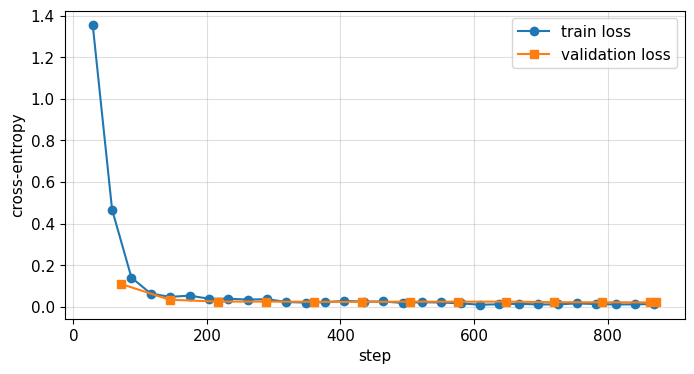

In [ ]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Гиперпараметры: learning rate 3e-5 (типичный диапазон 2e-5 - 5e-5 для BERT-base; 2e-4 из шаблона подходит маленьким моделям и для base было бы слишком много; слишком большой lr разрушил бы предобученные веса, а слишком маленький замедлил бы обучение), batch size 32 (размер батча, который помещается в память T4, обеспечивая при этом хорошую скорость обучения), выбраны 3 эпохи по условию (873 шага при 291 шаге на эпоху), линейный разгон 10% шагов (87) (плавный, необходим, чтобы на начальных шагах со случайными градиентами не произошло резкого скачка, который мог бы испортить предобученные веса энкодера), weight decay 0.01 (стандартная L2-регуляризация для трансформеров) и fp16 на GPU (включена для ускорения вычислений на GPU и экономии видеопамяти); eval каждые 72 шага (13 оценок за обучение). На кривых train loss падает с 1.356 до 0.011 - 0.013, validation loss с 0.109 (шаг 72) до 0.0337 (шаг 144) и 0.0210 в конце, то есть переобучения нет: eval loss не растёт, минимум достигнут в конце обучения; между 1-й и 2-й эпохами он держится на плато 0.023 - 0.025 и снижается по мере спада lr. Зазор между train (0.012) и validation (0.021) небольшой, больше эпох сильно не поможет, хотя по одному loss, без f1 по шагам, это утверждать строго нельзя. Обучение заняло 131.6 с на Tesla T4 (Kaggle) (9301 предложений, 3 эпохи).

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [ ]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = n_pred = n_gold = 0
    for g_tags, p_tags in zip(gold, pred):
        for g, p in zip(g_tags, p_tags):
            n_pred += p != 'O'
            n_gold += g != 'O'
            tp += (p != 'O') and (p == g)
    if n_pred + n_gold == 0 or tp == 0:
        return 0.0
    return 2 * tp / (n_pred + n_gold)

In [ ]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]

val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)

print('VALIDATION')
print(classification_report(val_gold, val_pred, digits=4, zero_division=0))
print('TEST')
print(classification_report(test_gold, test_pred, digits=4, zero_division=0))

final = entity_scores(test_gold, test_pred)
final['token_f1'] = token_f1(test_gold, test_pred)
rep = classification_report(test_gold, test_pred, output_dict=True, zero_division=0)
final['per_type'] = {t: rep[t] for t in ENTITY_TYPES if t in rep}
final['val'] = dict(**entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred))
print('VAL  ', {k: round(float(v), 4) for k, v in final['val'].items()})
print('TEST ', {k: round(float(v), 4) for k, v in final.items() if k in ('f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1')})

VALIDATION
              precision    recall  f1-score   support

         LOC     0.9789    0.9914    0.9851      1168
         ORG     0.9288    0.9480    0.9383      1308
         PER     0.9951    0.9976    0.9963      1641

   micro avg     0.9693    0.9801    0.9746      4117
   macro avg     0.9676    0.9790    0.9733      4117
weighted avg     0.9695    0.9801    0.9747      4117

TEST
              precision    recall  f1-score   support

         LOC     0.9757    0.9915    0.9835      1175
         ORG     0.9347    0.9459    0.9402      1256
         PER     0.9968    0.9975    0.9971      1570

   micro avg     0.9710    0.9795    0.9752      4001
   macro avg     0.9691    0.9783    0.9736      4001
weighted avg     0.9711    0.9795    0.9753      4001

VAL   {'f1_micro': 0.9746, 'f1_macro': 0.9733, 'precision': 0.9693, 'recall': 0.9801, 'token_f1': 0.9808}
TEST  {'f1_micro': 0.9752, 'f1_macro': 0.9736, 'precision': 0.971, 'recall': 0.9795, 'token_f1': 0.9807}


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Хуже всего распознаётся ORG: f1 0.9383 на validation и 0.9402 на test против LOC 0.9851 / 0.9835 и PER 0.9963 / 0.9971. Причина не в частоте (ORG в train 5960 примеров, больше, чем LOC 4881), а в разнообразии: аббревиатуры, названия в кавычках, длинные многословные названия (6.8% спанов ORG длиннее 4 слов, у LOC 0.9%), неоднозначность ORG/LOC (ЕС, Кремль, Домодедово) и разнобой границ в разметке; PER устроен регулярно (в основном "Имя Фамилия" с заглавными буквами). Micro f1: 0.9746 val, 0.9752 test; macro f1: 0.9733 и 0.9736, немного ниже (на 0.0013 - 0.0016). Micro f1 рассчитывается по суммарным TP, FP и FN всех типов, macro f1 - как среднее f1 трёх типов. Высокое качество на наиболее многочисленном PER способствует тому, что micro f1 немного выше macro f1. Токенный f1 (0.9808 val, 0.9807 test) выше f1 по сущностям (на 0.006 и 0.0055): он даёт частичные очки за спан с неточной границей (верные слова внутри), а f1 по сущностям засчитывает спан только при совпадении обеих границ и типа. Пользователю NER обычно нужна целая сущность, поэтому ближе f1 по сущностям; токенный f1 показывает, что значительная часть ошибок только в границах. Близкие результаты на validation и test не показывают заметного разрыва качества между этими сплитами, сами по себе не доказывают отсутствие переобучения.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [ ]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    gold_spans = [tuple(s) for s in gold_spans]
    pred_spans = [tuple(s) for s in pred_spans]
    overlap = lambda a, b: a[0] < b[1] and b[0] < a[1]
    result, pred_used = [], set()
    for g in gold_spans:
        over = [p for p in pred_spans if overlap(g, p)]
        pred_used.update(over)
        if g in pred_spans:
            result.append(('correct', g, g))
            continue
        same_type = [p for p in over if p[2] == g[2]]
        if same_type:
            result.append(('boundary', g, same_type[0]))
        elif over:
            result.append(('type', g, over[0]))
        else:
            result.append(('missed', g, None))
    for p in pred_spans:
        if p not in pred_used:
            result.append(('spurious', None, p))
    return result

In [ ]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

err_counter = collections.Counter()
N_EX = 6
examples = {c: [] for c in ERROR_CATEGORIES[1:]}
seen_sent = {c: set() for c in examples}
for i, (g_tags, p_tags) in enumerate(zip(val_gold, val_pred)):
    for cat, gs, ps in categorize_errors(bio_to_spans(g_tags), bio_to_spans(p_tags)):
        err_counter[cat] += 1
        if cat != 'correct' and len(examples[cat]) < N_EX and i not in seen_sent[cat]:
            seen_sent[cat].add(i)
            examples[cat].append((i, gs, ps))
errors = {c: err_counter[c] for c in ERROR_CATEGORIES}
n_err = sum(errors[c] for c in ERROR_CATEGORIES[1:])
print(errors)
for c in ERROR_CATEGORIES[1:]:
    print(f'{c:<9} {errors[c]:>6}  доля среди ошибок {errors[c] / max(n_err, 1):.1%}')


def fmt(words, s):
    return 'None' if s is None else f"«{' '.join(words[s[0]:s[1]])}» [{s[2]}]"


def window(words, gs, ps, pad=6):
    spans = [s for s in (gs, ps) if s is not None]
    lo, hi = max(0, min(s[0] for s in spans) - pad), min(len(words), max(s[1] for s in spans) + pad)
    return ('... ' if lo else '') + ' '.join(words[lo:hi]) + (' ...' if hi < len(words) else '')


for c, exs in examples.items():
    print(f'\n{c}')
    for i, gs, ps in exs:
        words = val_tokens[i]
        print(window(words, gs, ps))
        print('   gold:', fmt(words, gs), '| pred:', fmt(words, ps))

{'correct': 4035, 'boundary': 65, 'type': 9, 'missed': 8, 'spurious': 50}
boundary      65  доля среди ошибок 49.2%
type           9  доля среди ошибок 6.8%
missed         8  доля среди ошибок 6.1%
spurious      50  доля среди ошибок 37.9%

boundary
... стал редактором костромской областной молодежной газеты " Молодежная линия " , затем возглавил Костромскую государственную телерадиокомпанию ...
   gold: «Молодежная линия» [ORG] | pred: «" Молодежная линия "» [ORG]
... уже в конце года стал руководителем Федеральной службы по надзору в сфере связи , информационных технологий и массовых коммуникаций .
   gold: «Федеральной службы по надзору в сфере связи» [ORG] | pred: «Федеральной службы по надзору в сфере связи , информационных технологий и массовых коммуникаций» [ORG]
С . Ситников является председателем Федеральной конкурсной комиссии по телерадиовещанию , входит в состав Госкомиссии по ...
   gold: «Федеральной конкурсной комиссии» [ORG] | pred: «Федеральной конкурсной комиссии по т

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** На validation: correct 4035, boundary 65, type 9, missed 8, spurious 50; самая частая ошибка boundary (49.2% от 132 ошибок), затем spurious (37.9%), type (6.8%) и missed (6.1%). Общее по примерам: в boundary все 6 показанных случаев ORG, модель включает или не включает кавычки ("Молодежная линия"), отрезает или добавляет хвост у длинных названий (Федеральной службы по надзору в сфере связи, ... информационных технологий и массовых коммуникаций; Совета глав МИД); в type аббревиатуры и метонимии, где ORG и LOC неразличимы (ЕС, ЕЭС, МСФО, Домодедово, "Центр"), настоящая ошибка модели только "Гусеву" (PER -> LOC); в missed редкие аббревиатуры (БКК) и названия программ; spurious это спаны, которых нет в разметке (Министерство, Системного оператора, Кремля), плюс "баронесса" и "России" в "Герой России". Ошибки разметки, а не модели, в показанной выборке: gold "Ваш" как PER и "Губернатора" как PER, "FM - радиостанцию" как ORG, незамеченные организации (Министерство, Системного оператора), усечённые названия (Федеральной конкурсной комиссии без "по телерадиовещанию", "Азии AIA Group" с лишним "Азии"); значит, часть boundary и spurious ошибок это разнобой разметки, что затрудняет обучение и содержательно правдоподобный ответ модели может не совпадать с эталоном. Чтобы уменьшить boundary, я бы сначала приняла соглашения о границах (кавычки, хвосты названий) в train и test или посчитала мягкую метрику с частичным совпадением, а затем попробовала бы CRF-слой или декодирование спанов и усреднение нескольких запусков.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [ ]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
count_trainable = lambda m: sum(p.numel() for p in m.parameters() if p.requires_grad)


def run_frozen(lr, tag):
    set_seed(SEED)
    m = make_model()
    _, sec = train_ner(m, tokenized['train'], tokenized['validation'], lr=lr,
                       freeze_encoder=True, out_dir=f'runs/freeze_{tag}')
    pred = predict_word_tags(m, val_tokens)
    res = dict(**entity_scores(val_gold, pred), token_f1=token_f1(val_gold, pred),
               train_sec=sec, trainable_params=count_trainable(m), lr=lr)
    del m
    return res


ablation = {
    'setting': ABLATION,
    'full_finetune': dict(**entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred),
                          train_sec=RUN_TIMES['train_main_sec'], trainable_params=count_trainable(model), lr=LR),
    'frozen_encoder': run_frozen(LR, 'same_lr'),
    'frozen_encoder_lr_1e-3': run_frozen(1e-3, 'lr1e3'),
}
print(json.dumps(ablation, ensure_ascii=False, indent=2, default=float))

{'loss': '1.936', 'grad_norm': '5.092', 'learning_rate': '9.655e-06', 'epoch': '0.09966'}
{'loss': '1.885', 'grad_norm': '4.908', 'learning_rate': '1.966e-05', 'epoch': '0.1993'}
{'eval_loss': '1.759', 'eval_runtime': '2.243', 'eval_samples_per_second': '960.1', 'eval_steps_per_second': '7.581', 'epoch': '0.2474'}
{'loss': '1.783', 'grad_norm': '4.705', 'learning_rate': '2.966e-05', 'epoch': '0.299'}
{'loss': '1.638', 'grad_norm': '4.616', 'learning_rate': '2.893e-05', 'epoch': '0.3986'}
{'eval_loss': '1.395', 'eval_runtime': '2.255', 'eval_samples_per_second': '955', 'eval_steps_per_second': '7.54', 'epoch': '0.4948'}
{'loss': '1.501', 'grad_norm': '4.28', 'learning_rate': '2.782e-05', 'epoch': '0.4983'}
{'loss': '1.378', 'grad_norm': '3.991', 'learning_rate': '2.672e-05', 'epoch': '0.5979'}
{'loss': '1.272', 'grad_norm': '3.799', 'learning_rate': '2.561e-05', 'epoch': '0.6976'}
{'eval_loss': '1.125', 'eval_runtime': '2.266', 'eval_samples_per_second': '950', 'eval_steps_per_second': 

{'loss': '1.703', 'grad_norm': '3.44', 'learning_rate': '0.0003218', 'epoch': '0.09966'}
{'loss': '0.8256', 'grad_norm': '0.855', 'learning_rate': '0.0006552', 'epoch': '0.1993'}
{'eval_loss': '0.4562', 'eval_runtime': '2.261', 'eval_samples_per_second': '952.3', 'eval_steps_per_second': '7.519', 'epoch': '0.2474'}
{'loss': '0.4935', 'grad_norm': '0.7911', 'learning_rate': '0.0009885', 'epoch': '0.299'}
{'loss': '0.3428', 'grad_norm': '0.3101', 'learning_rate': '0.0009644', 'epoch': '0.3986'}
{'eval_loss': '0.2043', 'eval_runtime': '2.264', 'eval_samples_per_second': '951.1', 'eval_steps_per_second': '7.51', 'epoch': '0.4948'}
{'loss': '0.2608', 'grad_norm': '0.4375', 'learning_rate': '0.0009275', 'epoch': '0.4983'}
{'loss': '0.2323', 'grad_norm': '0.3409', 'learning_rate': '0.0008906', 'epoch': '0.5979'}
{'loss': '0.2116', 'grad_norm': '0.2657', 'learning_rate': '0.0008537', 'epoch': '0.6976'}
{'eval_loss': '0.1525', 'eval_runtime': '2.258', 'eval_samples_per_second': '953.4', 'eval_s

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Замороженный энкодер при том же lr 3e-5 почти ничего не выучил: f1 micro 0.0005 (precision 0.083, recall 0.0002), loss упал только с 1.94 до 0.64, то есть случайно инициализированная голова за 873 шага при таком lr не обучилась. При lr 1e-3 (контроль, чтобы отделить эффект lr от эффекта заморозки) f1 micro 0.8438 (precision 0.823, recall 0.865, token f1 0.8967), то есть на 0.131 ниже полного дообучения (0.9746 на validation). Время 60.0 с против 131.6 с (в 2.2 раза быстрее), обучаемых параметров 5 383 против 177 268 231 (0.003%). На мой взгляд, признаки предобученного BERT получены под языковое моделирование, а границы и типы сущностей требуют подстройки слоёв энкодера; голова одна этого не даёт, а экономия времени небольшая, прямой проход по всем 12 слоям всё равно нужен. Также вывод ограничен: один seed, lr для замороженного варианта проверен только на двух значениях, loss при lr 1e-3 ещё слегка снижался (0.0911), так что разрыв мог бы сократиться. Следующим шагом я бы подобрала lr для заморозки (3e-4, 3e-3), дала больше эпох, повторила на нескольких seed и сравнила с частичной разморозкой верхних слоёв.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** На validation дообученный rubert-base-cased получил f1 по сущностям 0.9746 против 0.5613 у словарного бейзлайна и 0.0250 у энкодера со случайной головой. На test итоговый f1 составил 0.9752, macro f1 - 0.9736, токенный f1 - 0.9807. Самый слабый тип ORG (f1 0.940 против PER 0.997): из 132 ошибок на validation 49% ошибки границ и 38% лишние спаны, и в просмотренных примерах заметная часть связана с непоследовательной разметкой (кавычки, пропущенные организации, титулы), что затрудняет обучение и содержательно правдоподобный ответ модели может не совпадать с эталоном. Абляция: замороженный энкодер при том же lr не обучился (micro f1 0.0005), при lr 1e-3 дал 0.8438 при времени в 2.2 раза меньше, поэтому полное дообучение оправдано. Главные ограничения: использовался один seed без подбора гиперпараметров, один новостной домен, шум разметки и нечувствительность модели к тексту без заглавных букв. Дальше я бы очистила или унифицировала границы разметки, повторила эксперименты на нескольких seed, проверила модель на другом домене (FactRuEval или NEREL) и добавила аугментацию регистром и CRF-слой.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [ ]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "DeepPavlov/rubert-base-cased", "revision": "4036cab694767a299f2b9e6492909664d9414229", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 177268231, "ablation": {"setting": "freeze", "full_finetune": {"f1_micro": 0.9746376811594203, "f1_macro": 0.9732628398654871, "precision": 0.9692529425894787, "recall": 0.980082584406121, "token_f1": 0.980806142034549, "train_sec": 131.62294660099997, "trainable_params": 177268231, "lr": 3e-05}, "frozen_encoder": {"f1_micro": 0.0004843787842092516, "f
final F1 micro 0.9752


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [ ]:
if '6.1' in BONUS_TASKS:
    from datasets import Dataset

    OWN_TEXT = """
Писатель [Виктор Пелевин|PER] представил новую книгу в [Москве|LOC] .
Футбольный клуб [Зенит|ORG] обыграл [Спартак|ORG] на стадионе в [Санкт - Петербурге|LOC] .
Компания [Яндекс|ORG] открыла новый центр обработки данных во [Владимире|LOC] .
Учёные из [Новосибирского государственного университета|ORG] изучили озеро [Байкал|LOC] .
[Юрий Гагарин|PER] стартовал с космодрома [Байконур|LOC] в 1961 году .
Правление [Сбербанка|ORG] обсудило новую стратегию развития .
Поезд из [Екатеринбурга|LOC] прибыл в [Пермь|LOC] с опозданием .
Шахматист [Ян Непомнящий|PER] приехал на турнир в [Нидерланды|LOC] .
[Министерство здравоохранения|ORG] опубликовало новые рекомендации для пациентов .
[Александр Пушкин|PER] родился в [Москве|LOC] , а умер в [Петербурге|LOC] .
Кинофестиваль пройдёт в [Сочи|LOC] в июне .
Компания [SpaceX|ORG] запустила очередную ракету с мыса [Канаверал|LOC] .
[Лев Толстой|PER] жил в имении [Ясная Поляна|LOC] .
Спортсмены из [Казани|LOC] выступят на чемпионате [Европы|LOC] .
[Роскосмос|ORG] и [NASA|ORG] обсуждают совместные программы .
Гора [Эльбрус|LOC] находится на [Северном Кавказе|LOC] .
[Следственный комитет|ORG] возбудил дело по факту пожара в [Красноярске|LOC] .
Река [Лена|LOC] впадает в [Северный Ледовитый океан|LOC] .
Врач [Леонид Рошаль|PER] выступил на конференции в [Самаре|LOC] .
Футболист [Фёдор Смолов|PER] подписал контракт с клубом [Динамо|ORG] .
Выставка современного искусства открылась в [Третьяковской галерее|ORG] .
Туристы из [Германии|LOC] отдыхают в [Республике Алтай|LOC] .
Губернатор [Краснодарского края|LOC] открыл новую школу в [Анапе|LOC] .
[МВД|ORG] сообщило о задержании мошенников в [Ростове - на - Дону|LOC] .
[МИД|ORG] выразил протест после заявления посла .
[ФСБ|ORG] предотвратила кибератаку на крупные банки .
Композитор [Пётр Чайковский|PER] родился в [Воткинске|LOC] .
Актриса [Чулпан Хаматова|PER] приехала в [Казань|LOC] на фестиваль .
В [МГУ|ORG] открылась новая лаборатория искусственного интеллекта .
Компания [Ozon|ORG] построила новый склад под [Тверью|LOC] .
Хоккейный клуб [СКА|ORG] проиграл [ЦСКА|ORG] со счётом 2:3 .
Остров [Сахалин|LOC] омывается водами [Охотского моря|LOC] .
Оператор [МТС|ORG] расширил покрытие сети в [Республике Тыва|LOC] .
Депутаты [Государственной думы|ORG] рассмотрели законопроект о защите данных .
Лётчик [Валерий Чкалов|PER] перелетел из [Москвы|LOC] в [США|LOC] через [Северный полюс|LOC] .
Директор [Эрмитажа|ORG] [Михаил Пиотровский|PER] рассказал о планах реставрации .
Альпинисты поднялись на [Эверест|LOC] со стороны [Непала|LOC] .
Телеканал [РБК|ORG] сообщил о росте цен на бензин .
[Лаборатория Касперского|ORG] обнаружила вирус , который атаковал компьютеры в [Бразилии|LOC] .
[Фёдор Достоевский|PER] жил в [Петербурге|LOC] недалеко от [Сенной площади|LOC] .
[Банк России|ORG] сохранил ключевую ставку на прежнем уровне .
Гроссмейстер [Магнус Карлсен|PER] из [Норвегии|LOC] победил в турнире .
Стартапы из [Сколково|ORG] получили гранты на развитие .
Сборная [России|LOC] по биатлону выиграла эстафету в [Австрии|LOC] .
Поэт [Иосиф Бродский|PER] родился в [Ленинграде|LOC] .
Лекцию прочитал профессор [А . Н . Петров|PER] из [Томского политехнического университета|ORG] .
Автор статьи [Анна Смирнова|PER] работает в газете « [Коммерсантъ|ORG] » .
[Прокуратура Тульской области|ORG] проверит сообщение о нарушениях .
[Лукойл|ORG] планирует увеличить добычу нефти в [Западной Сибири|LOC] .
Исследователи из [Оксфордского университета|ORG] изучили климат [Арктики|LOC] .
Футболист [Лионель Месси|PER] долго выступал за клуб [Барселона|ORG] .
Самолёт авиакомпании [Аэрофлот|ORG] вылетел из [Шереметьево|LOC] в [Токио|LOC] .
Мэр [Нью - Йорка|LOC] встретился с делегацией из [Москвы|LOC] .
Экспедиция отправилась на озеро [Ладога|LOC] .
Режиссёр [Андрей Тарковский|PER] снимал фильмы в [СССР|LOC] и [Италии|LOC] .
[Европейский союз|ORG] ввёл новые правила для импорта товаров .
Центр управления полётами находится в [Королёве|LOC] под [Москвой|LOC] .
Хирург [Николай Склифосовский|PER] работал в [Москве|LOC] и [Киеве|LOC] .
Новую трассу проложили из [Белгородской области|LOC] в [Курскую область|LOC] .
Погода в выходные будет тёплой и солнечной .
Российские учёные создали новый материал для аккумуляторов .
Россияне всё чаще покупают товары через интернет .
Эксперты ожидают снижения инфляции в следующем году .
"""
    Path('own_annotations.txt').write_text(OWN_TEXT.strip() + '\n', encoding='utf-8')

    def parse_line(line):
        tokens, tags = [], []
        for m in re.finditer(r'\[([^\]|]+)\|([A-Z]+)\]|(\S+)', line):
            if m.group(3):
                tokens.append(m.group(3)); tags.append('O')
            else:
                for k, w in enumerate(m.group(1).split()):
                    tokens.append(w); tags.append(('B-' if k == 0 else 'I-') + m.group(2))
        assert all(t in label2id for t in tags), line
        return tokens, [label2id[t] for t in tags]

    parsed = [parse_line(l) for l in OWN_TEXT.strip().splitlines() if l.strip()]
    own = Dataset.from_dict({'tokens': [p[0] for p in parsed], 'ner_tags': [p[1] for p in parsed]})
    split = own.train_test_split(test_size=0.5, seed=SEED)
    own_train, own_test = split['train'], split['test']
    print(f'размечено {len(own)} предложений, train {len(own_train)}, test {len(own_test)}')

    def evaluate(m, ds):
        toks = [list(x) for x in ds['tokens']]
        gold = [[LABEL_NAMES[i] for i in t] for t in ds['ner_tags']]
        return entity_scores(gold, predict_word_tags(m, toks))

    to_list = lambda ds: ([list(x) for x in ds['tokens']], [list(x) for x in ds['ner_tags']])
    base_tr = data['train']
    bt, bn = to_list(base_tr)
    ot, on = to_list(own_train)
    REP = 10
    mix = Dataset.from_dict({'tokens': bt + ot * REP, 'ner_tags': bn + on * REP})
    ctrl = Dataset.from_dict({'tokens': bt, 'ner_tags': bn})
    tk = lambda ds: ds.map(tokenize_and_align, batched=True, remove_columns=ds.column_names)

    results_61 = {'before': {'own_test': evaluate(model, own_test), 'val': evaluate(model, data['validation'])}}
    for name, train_ds in [('control_no_own', ctrl), ('with_own', mix)]:
        set_seed(SEED)
        m = copy.deepcopy(model)
        train_ner(m, tk(train_ds), tokenized['validation'], epochs=3, lr=LR, out_dir=f'runs/own_{name}')
        results_61[name] = {'own_test': evaluate(m, own_test), 'val': evaluate(m, data['validation'])}
        del m
    for k, v in results_61.items():
        print(f'{k:<15} own_test F1 {v["own_test"]["f1_micro"]:.4f} | val F1 {v["val"]["f1_micro"]:.4f}')

размечено 63 предложений, train 31, test 32


{'loss': '0.00978', 'grad_norm': '0.5203', 'learning_rate': '9.655e-06', 'epoch': '0.09966'}
{'loss': '0.01065', 'grad_norm': '0.7444', 'learning_rate': '1.966e-05', 'epoch': '0.1993'}
{'eval_loss': '0.02538', 'eval_runtime': '2.312', 'eval_samples_per_second': '931.2', 'eval_steps_per_second': '7.352', 'epoch': '0.2474'}
{'loss': '0.01058', 'grad_norm': '1.578', 'learning_rate': '2.966e-05', 'epoch': '0.299'}
{'loss': '0.01214', 'grad_norm': '0.5255', 'learning_rate': '2.893e-05', 'epoch': '0.3986'}
{'eval_loss': '0.02938', 'eval_runtime': '2.335', 'eval_samples_per_second': '922', 'eval_steps_per_second': '7.28', 'epoch': '0.4948'}
{'loss': '0.01068', 'grad_norm': '0.1078', 'learning_rate': '2.782e-05', 'epoch': '0.4983'}
{'loss': '0.01676', 'grad_norm': '0.7439', 'learning_rate': '2.672e-05', 'epoch': '0.5979'}
{'loss': '0.009848', 'grad_norm': '0.3223', 'learning_rate': '2.561e-05', 'epoch': '0.6976'}
{'eval_loss': '0.03218', 'eval_runtime': '2.334', 'eval_samples_per_second': '922

{'loss': '0.01023', 'grad_norm': '0.04013', 'learning_rate': '9.667e-06', 'epoch': '0.09967'}
{'loss': '0.0109', 'grad_norm': '0.7056', 'learning_rate': '1.967e-05', 'epoch': '0.1993'}
{'eval_loss': '0.03053', 'eval_runtime': '2.33', 'eval_samples_per_second': '924', 'eval_steps_per_second': '7.296', 'epoch': '0.2492'}
{'loss': '0.01266', 'grad_norm': '0.3342', 'learning_rate': '2.967e-05', 'epoch': '0.299'}
{'loss': '0.01529', 'grad_norm': '0.4213', 'learning_rate': '2.893e-05', 'epoch': '0.3987'}
{'loss': '0.01897', 'grad_norm': '1.005', 'learning_rate': '2.782e-05', 'epoch': '0.4983'}
{'eval_loss': '0.02341', 'eval_runtime': '2.332', 'eval_samples_per_second': '923.3', 'eval_steps_per_second': '7.29', 'epoch': '0.4983'}
{'loss': '0.01725', 'grad_norm': '0.4653', 'learning_rate': '2.672e-05', 'epoch': '0.598'}
{'loss': '0.01588', 'grad_norm': '0.1333', 'learning_rate': '2.561e-05', 'epoch': '0.6977'}
{'eval_loss': '0.02867', 'eval_runtime': '2.357', 'eval_samples_per_second': '913.3'

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Размечено 63 предложения (59 с сущностями и 4 без; половина в train, половина в test: 31 и 32), короткие новостные и энциклопедические фразы современного стиля, часть на трудных случаях из 5.1 (Краснодарский край, Республика Алтай, Северный Кавказ, МВД, МИД, аббревиатуры). На подготовку данных и разметку ушло 5 часов. Инструкция разметки (файл own_annotations.txt, формат "[текст|ТИП]", слова через пробел, знаки препинания и дефисы отделены пробелами, как в Collection3): типы PER, ORG, LOC; PER имя и фамилия целиком, без должностей и званий; ORG компании, органы власти, университеты, клубы, СМИ и аббревиатуры (МВД, ФСБ); LOC страны, города, регионы, реки, озёра, горы, административные слова входят в спан, если это часть названия (Краснодарский край, Республика Алтай); не размечаются названия книг, фильмов и продуктов, этнонимы и прилагательные (россияне, российские), нарицательные слова; при вложенных сущностях размечается только внешняя. Результат f1 по сущностям: на моей тестовой части 0.9828 (до) -> 0.9915 (те же 3 эпохи без моих данных) -> 1.0000 (с моими данными), на validation Collection3 0.9746 -> 0.9706 -> 0.9737. Разница на моём тесте до 0.009, на validation различия до 0.004; наблюдаемый прирост небольшой, тест содержит всего 32 предложения. Сомневалась в разметке: Сколково (ORG или LOC), Третьяковская галерея (организация или место), "сборная России" (страна или команда), Байконур, "клуб Барселона" (клуб или город).

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [ ]:
MODEL2_ID = 'cointegrated/rubert-tiny2'
REV2 = HfApi().model_info(MODEL2_ID).sha
print('REV2 =', REV2)

REV2 = e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae


In [ ]:
if '6.2' in BONUS_TASKS:
    MODEL2_ID = 'cointegrated/rubert-tiny2'
    REV2 = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
    tok2 = AutoTokenizer.from_pretrained(MODEL2_ID, revision=REV2)
    assert tok2.is_fast
    tokenized2 = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(tok=tok2))
    set_seed(SEED)
    model2 = make_model(MODEL2_ID, REV2)
    _, sec2 = train_ner(model2, tokenized2['train'], tokenized2['validation'], lr=2e-4, tok=tok2, out_dir='runs/model2')

    def timed_predict(m, tok, toks):
        if device.type == 'cuda':
            torch.cuda.synchronize()
        t = time.perf_counter()
        pred = predict_word_tags(m, toks, tok=tok)
        if device.type == 'cuda':
            torch.cuda.synchronize()
        return pred, time.perf_counter() - t

    test_tokens = [list(ws) for ws in data['test']['tokens']]
    test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
    cmp62 = {}
    for name, m, tk_, train_sec in [(MODEL_ID, model, tokenizer, RUN_TIMES['train_main_sec']), (MODEL2_ID, model2, tok2, sec2)]:
        timed_predict(m, tk_, val_tokens[:64])
        pv, t_inf = timed_predict(m, tk_, val_tokens)
        pt, _ = timed_predict(m, tk_, test_tokens)
        n_par = sum(p.numel() for p in m.parameters())
        cmp62[name] = dict(params=n_par, size_mb_fp32=n_par * 4 / 2**20, train_sec=train_sec, infer_sec_val=t_inf,
                           val=entity_scores(val_gold, pv), test=entity_scores(test_gold, pt))
        r = cmp62[name]
        print(f'{name:<30} params {n_par/1e6:6.1f}M ({r["size_mb_fp32"]:.0f} MB fp32) | train {train_sec:7.1f}s | '
              f'infer val {t_inf:5.2f}s | val F1 {r["val"]["f1_micro"]:.4f} | test F1 {r["test"]["f1_micro"]:.4f}')
    del model2
    torch.cuda.empty_cache()

{'loss': '1.406', 'grad_norm': '1.448', 'learning_rate': '6.437e-05', 'epoch': '0.09966'}
{'loss': '0.4652', 'grad_norm': '0.8541', 'learning_rate': '0.000131', 'epoch': '0.1993'}
{'eval_loss': '0.2046', 'eval_runtime': '0.4998', 'eval_samples_per_second': '4308', 'eval_steps_per_second': '34.01', 'epoch': '0.2474'}
{'loss': '0.229', 'grad_norm': '1.031', 'learning_rate': '0.0001977', 'epoch': '0.299'}
{'loss': '0.142', 'grad_norm': '1.609', 'learning_rate': '0.0001929', 'epoch': '0.3986'}
{'eval_loss': '0.0724', 'eval_runtime': '0.4974', 'eval_samples_per_second': '4329', 'eval_steps_per_second': '34.18', 'epoch': '0.4948'}
{'loss': '0.1085', 'grad_norm': '2.162', 'learning_rate': '0.0001855', 'epoch': '0.4983'}
{'loss': '0.09956', 'grad_norm': '1.603', 'learning_rate': '0.0001781', 'epoch': '0.5979'}
{'loss': '0.0865', 'grad_norm': '0.4411', 'learning_rate': '0.0001707', 'epoch': '0.6976'}
{'eval_loss': '0.0551', 'eval_runtime': '0.4946', 'eval_samples_per_second': '4353', 'eval_step

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Больше качество у DeepPavlov/rubert-base-cased: test f1 0.9752 против 0.9314 у cointegrated/rubert-tiny2 (на validation 0.9746 против 0.9303), то есть +0.044. Цена: 180M параметров (676 МБ) против 29.1M (111 МБ), то есть в 6 раза больше; обучение 131.6 с против 27.7 с (в 4.75 раза дольше); инференс на validation 2.35 с против 1.06 с (в 2.2 раза дольше, замер включает токенизацию и постобработку). Для честности одинаковы датасет и сплиты, число эпох (3), batch 32, MAX_LENGTH 128, seed 0, метрика (seqeval по словам) и железо (одна T4 в одной сессии). Различается learning rate (3e-5 у base, 2e-4 у tiny: каждой модели взят типичный для её размера) и токенизатор (у каждой модели свой).

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [ ]:
if '6.3' in BONUS_TASKS:
    translit = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя', ['a','b','v','g','d','e','e','zh','z','i','y','k','l','m','n','o','p','r','s','t','u','f','kh','ts','ch','sh','sch','','y','','e','yu','ya']))

    def typos(words, p=0.15, seed=0):
        rng = random.Random(seed)
        out = []
        for w in words:
            if len(w) > 3 and rng.random() < p:
                i = rng.randrange(len(w) - 1)
                w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
            out.append(w)
        return out

    def to_translit(words):
        def tr(c):
            t = translit.get(c.lower())
            if t is None:
                return c
            return t.capitalize() if c.isupper() else t
        return [''.join(tr(c) for c in w) or w for w in words]

    corruptions = {
        'clean': lambda ws: ws,
        'lowercase': lambda ws: [w.lower() for w in ws],
        'uppercase': lambda ws: [w.upper() for w in ws],
        'translit': to_translit,
    }
    shift_results = {}
    for name, fn in corruptions.items():
        shift_results[name] = entity_scores(val_gold, predict_word_tags(model, [fn(ws) for ws in val_tokens]))
    runs = []
    for sd in range(3):
        pred = predict_word_tags(model, [typos(ws, seed=sd * 100003 + i) for i, ws in enumerate(val_tokens)])
        runs.append(entity_scores(val_gold, pred))
    shift_results['typos_15%'] = {k: float(np.mean([r[k] for r in runs])) for k in runs[0]}
    shift_results['typos_15%']['f1_micro_std'] = float(np.std([r['f1_micro'] for r in runs]))
    for name, r in shift_results.items():
        print(f'{name:<10} F1 micro {r["f1_micro"]:.4f}  P {r["precision"]:.4f}  R {r["recall"]:.4f}')
    print('typos_15%: std F1 по 3 seed', round(shift_results['typos_15%']['f1_micro_std'], 4))

clean      F1 micro 0.9746  P 0.9693  R 0.9801
lowercase  F1 micro 0.2760  P 0.6190  R 0.1776
uppercase  F1 micro 0.3274  P 0.3460  R 0.3107
translit   F1 micro 0.6316  P 0.7035  R 0.5730
typos_15%  F1 micro 0.9448  P 0.9411  R 0.9486
typos_15%: std F1 по 3 seed 0.0025


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Сильнее всего f1 роняет приведение к нижнему регистру: 0.9746 -> 0.2760 (-0.70; precision 0.619, recall 0.178), следом верхний регистр 0.3274 (-0.65), затем транслит 0.6316 (-0.34), а опечатки в 15% слов почти не мешают: 0.9448 (-0.03; среднее по 3 seed, std 0.0025). Модель cased и, судя по результатам, опирается на заглавную букву как на главный признак имени собственного: без неё recall падает до 0.18 (модель почти перестаёт предсказывать сущности, и верными остаются самые уверенные), а слова в нижнем регистре токенизатор режет на другие сабворды, чем в train. При верхнем регистре все слова выглядят заглавными, precision (0.346) и recall (0.311) падают одновременно, вероятно, и из-за редких сабвордов в верхнем регистре. Транслит сохраняет заглавные буквы, и модель находит часть сущностей (recall 0.573), хотя слова режутся на латинские фрагменты. При опечатках (перестановка двух соседних букв) сохраняются заглавная буква и контекст, и большинство слов остаётся узнаваемым. Получается, что модель нельзя применять к тексту без заглавных букв (соцсети, поисковые запросы) без аугментации регистром.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [ ]:
if '6.4' in BONUS_TASKS:
    cpu = torch.device('cpu')
    cpu_model = copy.deepcopy(model).cpu().eval()
    quant_model = torch.ao.quantization.quantize_dynamic(copy.deepcopy(cpu_model), {torch.nn.Linear}, dtype=torch.qint8)
    sample = tokenizer(val_tokens[:32], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')

    def latency_ms(m, n=15):
        with torch.inference_mode():
            for _ in range(3):
                m(**sample)
            start = time.perf_counter()
            for _ in range(n):
                m(**sample)
        return (time.perf_counter() - start) / n * 1000

    def size_mb(m):
        torch.save(m.state_dict(), 'runs/tmp.pt')
        s = os.path.getsize('runs/tmp.pt') / 2**20
        os.remove('runs/tmp.pt')
        return s

    N_F1 = len(val_tokens)
    export_results = {}
    for name, m in [('fp32_cpu', cpu_model), ('int8_dynamic_cpu', quant_model)]:
        pred = predict_word_tags(m, val_tokens[:N_F1], dev=cpu)
        export_results[name] = dict(latency_ms=latency_ms(m), size_mb=size_mb(m), f1_micro=entity_scores(val_gold[:N_F1], pred)['f1_micro'])
    base_ms = export_results['fp32_cpu']['latency_ms']
    print(f'батч {tuple(sample["input_ids"].shape)}, F1 на всей validation ({N_F1} предложений), устройство: CPU')
    for k, v in export_results.items():
        print(f'{k:<18} {v["latency_ms"]:8.1f} ms  ускорение x{base_ms / v["latency_ms"]:.2f}  {v["size_mb"]:6.1f} MB  F1 {v["f1_micro"]:.4f}')

/tmp/ipykernel_50/3762688875.py:4: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  quant_model = torch.ao.quantization.quantize_dynamic(copy.deepcopy(cpu_model), {torch.nn.Linear}, dtype=torch.qint8)


батч (32, 43), F1 на всей validation (2153 предложений), устройство: CPU
fp32_cpu             1027.4 ms  ускорение x1.00   676.3 MB  F1 0.9746
int8_dynamic_cpu      871.6 ms  ускорение x1.18   433.3 MB  F1 0.9699


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Динамическая int8-квантизация линейных слоёв ускорила инференс на CPU (Kaggle) с 1027.4 до 871.6 мс на батч 32 x 43 токена (это среднее по 15 запускам после 3 прогревов, один и тот же батч), то есть в 1.18 раза; размер модели уменьшился с 676.3 до 433.3 МБ (в 1.56 раза). F1 на всей validation (2153 предложения) изменился с 0.9746 до 0.9699 (-0.0047), то есть упал незначительно. Выигрыш невелик, потому что 52% параметров (92.2M) это таблица эмбеддингов: она остаётся в fp32 (это обычный поиск по таблице, вычислений в ней почти нет), а квантизуются только линейные слои энкодера (85M параметров), в которых и сосредоточены вычисления; поэтому размер упал не в 4 раза, а в 1.56, а скорость выросла умеренно (часть операций, например внимание, остаётся в fp32). У модели с ещё большей долей эмбеддингов (например, xlm-roberta-base со словарём 250k) выигрыш по размеру был бы ещё меньше, а у модели, где вычислений в слоях больше, ускорение было бы заметнее.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean: лучший порог 0.760, val F1 0.9759 (при пороге 0: 0.9746, прирост +0.0012) | test: 0.9752 -> 0.9777 (+0.0024)
min: лучший порог 0.760, val F1 0.9756 (при пороге 0: 0.9746, прирост +0.0009) | test: 0.9752 -> 0.9785 (+0.0032)


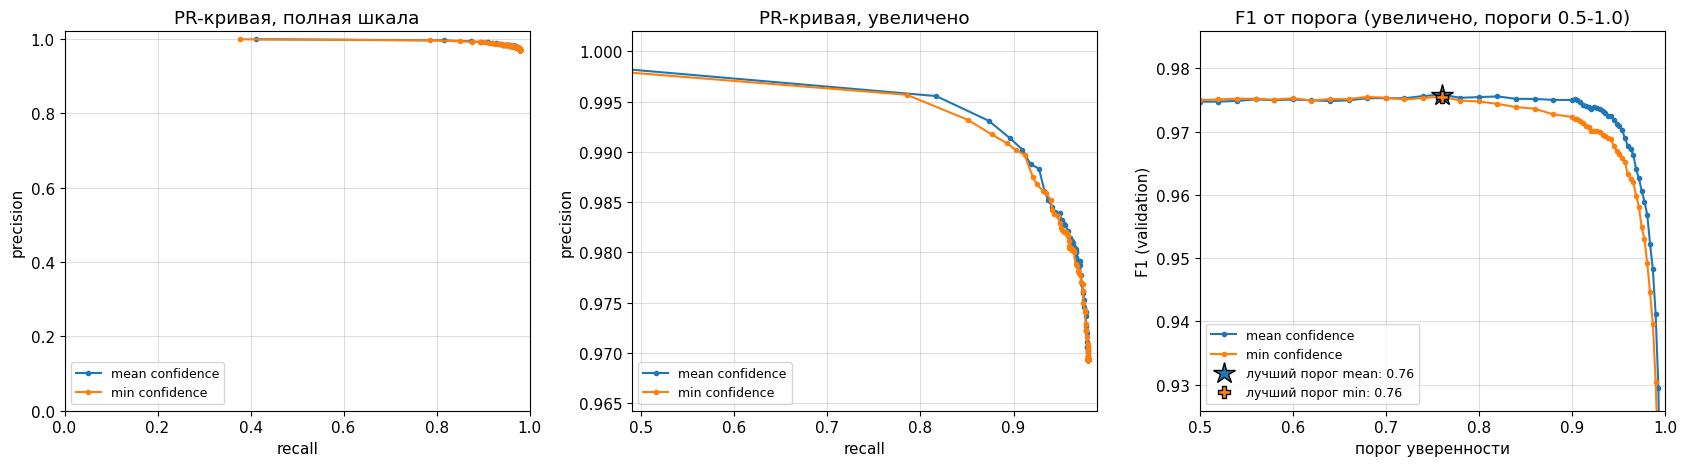

In [ ]:
if '6.5' in BONUS_TASKS:
    val_tags_p, val_probs_p = predict_word_tags(model, val_tokens, return_probs=True)
    test_tags_p, test_probs_p = predict_word_tags(model, test_tokens, return_probs=True)

    def with_conf(tags_l, probs_l):
        return [[(s, probs[s[0]:s[1]]) for s in bio_to_spans(tags)] for tags, probs in zip(tags_l, probs_l)]

    def score_at(cands, gold_l, agg, thr):
        tp = n_pred = n_gold = 0
        for cs, g in zip(cands, gold_l):
            gs = set(bio_to_spans(g))
            n_gold += len(gs)
            kept = [s for s, pr in cs if agg(pr) >= thr]
            n_pred += len(kept)
            tp += sum(s in gs for s in kept)
        p = tp / n_pred if n_pred else None
        r = tp / n_gold
        return p, r, (2 * p * r / (p + r) if p and r else 0.0)

    THRS = np.unique(np.concatenate([np.linspace(0, 0.9, 46), np.linspace(0.9, 0.999, 34)]))
    val_c, test_c = with_conf(val_tags_p, val_probs_p), with_conf(test_tags_p, test_probs_p)
    threshold_results, all_rows = {}, {}
    for name, agg in [('mean', np.mean), ('min', min)]:
        rows = [(t, *score_at(val_c, val_gold, agg, t)) for t in THRS]
        rows = [r for r in rows if r[1] is not None]
        all_rows[name] = rows
        best = max(rows, key=lambda r: r[3])
        test_0 = score_at(test_c, test_gold, agg, 0.0)[2]
        test_best = score_at(test_c, test_gold, agg, best[0])[2]
        threshold_results[name] = dict(best_thr=float(best[0]), best_f1=best[3], f1_at_0=rows[0][3],
                                       test_f1_at_0=test_0, test_f1_at_best=test_best)
        print(f'{name}: лучший порог {best[0]:.3f}, val F1 {best[3]:.4f} (при пороге 0: {rows[0][3]:.4f}, '
              f'прирост {best[3] - rows[0][3]:+.4f}) | test: {test_0:.4f} -> {test_best:.4f} ({test_best - test_0:+.4f})')

    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
    colors = {'mean': 'tab:blue', 'min': 'tab:orange'}
    for name, rows in all_rows.items():
        rec, prec = [r[2] for r in rows], [r[1] for r in rows]
        ax[0].plot(rec, prec, 'o-', ms=3, color=colors[name], label=f'{name} confidence')
        ax[1].plot(rec, prec, 'o-', ms=3, color=colors[name], label=f'{name} confidence')
        ax[2].plot([r[0] for r in rows], [r[3] for r in rows], 'o-', ms=3, color=colors[name], label=f'{name} confidence')
    for name, mk, ms in [('mean', '*', 16), ('min', 'P', 9)]:
        b = threshold_results[name]
        ax[2].plot(b['best_thr'], b['best_f1'], mk, ms=ms, color=colors[name], mec='k',
                   label=f'лучший порог {name}: {b["best_thr"]:.2f}')
    rmax = max(r[2] for rows in all_rows.values() for r in rows)
    pmin = min(r[1] for rows in all_rows.values() for r in rows if r[2] >= 0.5 * rmax)
    best_f1 = max(b['best_f1'] for b in threshold_results.values())
    ax[0].set(xlim=(0, 1), ylim=(0, 1.02), xlabel='recall', ylabel='precision', title='PR-кривая, полная шкала')
    ax[1].set(xlim=(0.5 * rmax, min(1.0, rmax + 0.01)), ylim=(pmin - 0.005, 1.002), xlabel='recall',
              ylabel='precision', title='PR-кривая, увеличено')
    ax[2].set(xlim=(0.5, 1.0), ylim=(best_f1 - 0.05, best_f1 + 0.01), xlabel='порог уверенности',
              ylabel='F1 (validation)', title='F1 от порога (увеличено, пороги 0.5-1.0)')
    for a in ax:
        a.grid(alpha=0.4)
        a.legend(loc='lower left', fontsize=9)
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Лучший порог 0.76 как для средней, так и для минимальной уверенности: на validation f1 0.9759 (mean, +0.0012 к порогу 0) и 0.9756 (min, +0.0009), на test (порог подобран на validation) 0.9752 -> 0.9777 (mean, +0.0024) и 0.9785 (min, +0.0032), то есть прирост небольшой, но совпадает по направлению на отложенной выборке. Средняя уверенность усредняет вероятности тегов слов спана, а минимальная берёт самое неуверенное слово: min строже для длинных спанов, где одно неуверенное слово отсекает весь спан, а у коротких (в основном 1-2 слова) обе почти совпадают, поэтому кривые близки. Порог не может поднять recall, потому что он только отбрасывает уже предсказанные спаны и не добавляет новых: recall максимален при пороге 0 (0.9801 на validation) и дальше только падает, а precision может увеличиваться за счёт удаления ложных срабатываний, поэтому F1 имеет небольшой максимум около 0.76.

In [ ]:
bonus = {}
for key, name in [('6.1', 'results_61'), ('6.2', 'cmp62'), ('6.3', 'shift_results'), ('6.4', 'export_results'), ('6.5', 'threshold_results')]:
    if key in BONUS_TASKS and name in globals():
        bonus[key] = globals()[name]
(ARTIFACTS / 'bonus_metrics.json').write_text(json.dumps(json_ready(bonus), ensure_ascii=False, indent=2), encoding='utf-8')
print(list(bonus))

['6.1', '6.2', '6.3', '6.4', '6.5']
